# CODE 5.4: Trade-off and Speed

> **Goal:** two last questions about the two models, before the demo.
>
> 1. **What would other limits have given?** Notebook 5.1 locked the limit of each model on March. Here we set the limits again with other budgets, and see what each one gives in the test months: leaks caught, how early, and how many false alarms.
> 2. **How fast is each model?** How long it takes to score one window, compared with the 5 minutes between two windows.
>
> - **Input:** `data/processed/grid.npz` and `data/processed/windows.parquet` (3.1), `results/time_split.csv` and `results/leaks.csv` (1.2), `results/signals_used.json` (4.1), `models/isolation_forest.joblib` (4.1), `models/lstm_autoencoder.pt` (4.2), `results/alarm_rules.json` (5.1), `results/window_scores.parquet` and `results/test_results.csv` (5.2), and `results/alarm_events.csv` (5.3).
> - **Output:** `results/tradeoff.csv`: what every budget gave in the test months. At the end you should see **ALL CHECKS PASSED**.

### A What-If After the Test

> Notebook 5.1 locked one limit per model: the lowest limit with at most **1 false alarm event per week** in March (the **budget**), with the unusual March hours left out. Notebook 5.2 then opened the test months once with these limits. That stays the official result.
>
> Here we ask what other budgets would have given. Each budget gives its own limit, found on March exactly as in notebook 5.1: a looser budget allows more false alarms in March, so its limit is lower.
>
> | Setting | Budget in March | March windows counted |
> | --- | --- | --- |
> | 0.5 | at most 0.5 false alarm events per week | unusual hours left out |
> | 1 (locked) | at most 1 | unusual hours left out: the locked limits of notebook 5.1 |
> | 2 | at most 2 | unusual hours left out |
> | 4 | at most 4 | unusual hours left out |
> | what-if | at most 1 | every window counted: the what-if limits of notebook 5.1 |
>
> The budgets were fixed before looking at what they give: half the locked budget, the locked budget, and twice and four times it.
>
> All of this is a **what-if after the test**: we already know how the test months went. Picking now the budget that looks best on them would be tuning on the test, like choosing a study plan after seeing the answers of the exam. So nothing here changes a rule, a limit or a result of notebook 5.2.

## Import Libraries & Variables

### Import Libraries

> - `os`, `json`, `hashlib`: folders and file paths, the rules file, and fingerprints of files.
> - `time`: a stopwatch (`time.perf_counter`) for the speed test.
> - `numpy`, `pandas`: numbers and tables.
> - `matplotlib`: charts.
> - `joblib`: loads the Isolation Forest of notebook 4.1.
> - `torch` (PyTorch): rebuilds the LSTM autoencoder of notebook 4.2.
> - `tqdm`: shows a progress bar while the limits are searched and the windows are timed.

In [1]:
import os
import json
import hashlib
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from tqdm import tqdm

### Variables

#### Folder Paths

> The inputs from notebooks 1.2 to 5.3, and the file this notebook writes.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isfile(os.path.join(ROOT_DIR, "requirements.txt")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

PROCESSED_DIR = os.path.join(ROOT_DIR, "data", "processed")
GRID_FILE = os.path.join(PROCESSED_DIR, "grid.npz")
WINDOWS_FILE = os.path.join(PROCESSED_DIR, "windows.parquet")
RESULTS_DIR = os.path.join(ROOT_DIR, "results")
SPLIT_FILE = os.path.join(RESULTS_DIR, "time_split.csv")
LEAKS_FILE = os.path.join(RESULTS_DIR, "leaks.csv")
SIGNALS_FILE = os.path.join(RESULTS_DIR, "signals_used.json")
RULES_FILE = os.path.join(RESULTS_DIR, "alarm_rules.json")
SCORES_FILE = os.path.join(RESULTS_DIR, "window_scores.parquet")
SUMMARY_FILE = os.path.join(RESULTS_DIR, "test_results.csv")
EVENTS_FILE = os.path.join(RESULTS_DIR, "alarm_events.csv")
TRADEOFF_FILE = os.path.join(RESULTS_DIR, "tradeoff.csv")
MODELS_DIR = os.path.join(ROOT_DIR, "models")
FOREST_FILE = os.path.join(MODELS_DIR, "isolation_forest.joblib")
LSTM_FILE = os.path.join(MODELS_DIR, "lstm_autoencoder.pt")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: predictive-maintenance-metropt


#### Settings

> - `OIL_COLUMN`, `WINDOW_STEPS`: as in notebook 4.2, to cut the windows for the LSTM. `TICK_SECONDS`: one tick of the grid is 10 seconds.
> - `MINUTES_PER_WEEK`: to count false alarms per week.
> - `BUDGETS`: the budgets tried, in false alarm events per week in March.
> - `SPEED_WINDOWS`: how many test windows are timed, one by one.
> - `MODEL_NAMES`, `MODEL_COLORS`, `VERSION_NAMES`: names and colors for tables and charts.
>
> The alarm rule, the locked budget and the rule for unusual March hours are not set here: they are read from `alarm_rules.json`.

In [3]:
OIL_COLUMN = "Oil_temperature"
WINDOW_STEPS = 360
TICK_SECONDS = 10
MINUTES_PER_WEEK = 7 * 24 * 60

BUDGETS = [0.5, 1, 2, 4]
SPEED_WINDOWS = 200

MODEL_NAMES = {"isolation_forest": "Isolation Forest", "lstm_autoencoder": "LSTM autoencoder"}
MODEL_COLORS = {"isolation_forest": "#1D9E75", "lstm_autoencoder": "#534AB7"}
VERSION_NAMES = {"main": "unusual hours left out", "all_counted": "every window counted"}

## Functions

### Record a Check

> `check()` prints PASS or FAIL for one check and stores the result in `results`.

In [4]:
results = {}

def check(name, ok):
    results[name] = bool(ok)
    print(("PASS  " if ok else "FAIL  ") + name)

### Fingerprints (from 5.1)

> `file_fingerprint()` and `rules_fingerprint()` are copied unchanged from notebook 5.1: a code of 64 characters computed from every byte of a file, or from the rules. If anything changed, the code changes completely.

In [5]:
def file_fingerprint(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

In [6]:
def rules_fingerprint(rules):
    text = json.dumps({key: value for key, value in rules.items() if key != "fingerprint"}, sort_keys=True)
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

### Mark the Unusual March Hours (from 5.1)

> `find_runs()` and `marked_windows()` are copied unchanged from notebook 5.1: the first finds every run of an on/off signal (its first tick and its length), the second marks every window that holds at least one marked tick.

In [7]:
def find_runs(is_on):
    edges = np.diff(np.concatenate([[0], is_on.astype(int), [0]]))
    starts = np.flatnonzero(edges == 1)
    return starts, np.flatnonzero(edges == -1) - starts

In [8]:
def marked_windows(marked_ticks, end_indices, window_steps):
    running_count = np.concatenate([[0], np.cumsum(marked_ticks)])
    return running_count[end_indices + 1] - running_count[end_indices + 1 - window_steps] > 0

### Alarms, Events and the Limit Search (from 5.1)

> Copied unchanged from notebook 5.1:
>
> - `alarm_windows()`: an alarm at every window that is the 3rd (or later) window in a row above the limit.
> - `find_events()`: alarms at most 60 minutes apart are one event.
> - `search_limit()`: tries every March score as the limit, from the highest to the lowest, and returns the lowest limit before the first one that breaks the budget.

In [9]:
def alarm_windows(scores, ends, limit, in_a_row, step_minutes):
    above = pd.Series(scores > limit)
    restart = ~above | pd.Series(ends.diff().to_numpy() != np.timedelta64(step_minutes, "m"))
    run = above.astype(int).groupby(restart.cumsum()).cumsum()
    return (run >= in_a_row).to_numpy()

In [10]:
def find_events(alarms, counted, ends, merge_gap_minutes):
    times = ends[alarms & counted].reset_index(drop=True)
    new_event = times.diff().isna() | (times.diff() > pd.Timedelta(minutes=merge_gap_minutes))
    events = times.groupby(new_event.cumsum()).agg(["min", "max", "size"])
    return events.rename(columns={"min": "first_alarm", "max": "last_alarm", "size": "alarms"}).reset_index(drop=True)

In [11]:
def search_limit(scores, ends, counted, max_events, in_a_row, step_minutes, merge_gap_minutes):
    chosen = None
    for limit in np.unique(scores)[::-1]:
        alarms = alarm_windows(scores=scores, ends=ends, limit=limit, in_a_row=in_a_row, step_minutes=step_minutes)
        if len(find_events(alarms=alarms, counted=counted, ends=ends, merge_gap_minutes=merge_gap_minutes)) > max_events:
            return chosen, limit
        chosen = limit
    return chosen, None

### Judge Each Leak (from 5.2)

> `judge_leaks()` is copied unchanged from notebook 5.2: for every leak, was it caught, when came the first alarm in its warning zone or during it, and the lead time (hours before the start; negative means after the start).

In [12]:
def judge_leaks(alarms, ends, zones, leak_numbers, leaks):
    rows = []
    for row in leaks.itertuples():
        own = alarms & (leak_numbers == row.leak)
        in_time = own & np.isin(zones, ["warning", "leak"])
        first = ends[in_time].min() if in_time.any() else pd.NaT
        rows.append({"leak": row.leak, "caught": bool(in_time.any()), "first_alarm": first,
                     "lead_time_hours": (row.start - first) / pd.Timedelta(hours=1) if in_time.any() else np.nan,
                     "alarms_in_warning_zone": int((own & (zones == "warning")).sum()),
                     "alarms_during_leak": int((own & (zones == "leak")).sum()),
                     "alarms_in_ignored_zone": int((own & (zones == "ignored")).sum())})
    return pd.DataFrame(rows)

### The Two Models (from 4.1 and 4.2)

> Copied unchanged, for the speed test: `anomaly_score()` from notebook 4.1 (the score of the forest), and `cut_windows()`, `LSTMAutoencoder` and `window_errors()` from notebook 4.2 (cut the windows out of the grid, the LSTM itself, and its error for every window).

In [13]:
def anomaly_score(model, features):
    return -model.score_samples(features)

In [14]:
def cut_windows(grid_values, end_indices, window_steps, oil_index):
    ticks = end_indices[:, None] - window_steps + 1 + np.arange(window_steps)[None, :]
    windows = grid_values[ticks]
    windows[:, :, oil_index] -= windows[:, :1, oil_index]
    return windows

In [15]:
class LSTMAutoencoder(torch.nn.Module):
    def __init__(self, n_signals, memory_size):
        super().__init__()
        self.encoder = torch.nn.LSTM(input_size=n_signals, hidden_size=memory_size, batch_first=True)
        self.decoder = torch.nn.LSTM(input_size=memory_size, hidden_size=memory_size, batch_first=True)
        self.output = torch.nn.Linear(in_features=memory_size, out_features=n_signals)

    def forward(self, windows):
        _, (memory, _) = self.encoder(windows)
        note = memory[-1].unsqueeze(1).repeat(1, windows.shape[1], 1)
        redrawn, _ = self.decoder(note)
        return self.output(redrawn)

In [16]:
def window_errors(model, windows, batch_size):
    model.eval()
    parts = []
    with torch.no_grad():
        for start in range(0, len(windows), batch_size):
            batch = windows[start:start + batch_size]
            parts.append((model(batch) - batch).abs().mean(dim=1).cpu())
    per_signal = torch.cat(parts).numpy()
    return per_signal.mean(axis=1), per_signal

## Load Everything

### Read the Files

> The scores and errors of every window come from notebook 5.2, so no window is scored again for the trade-off. The rules come from notebook 5.1, and the fingerprint of the rules file must still match its content.

In [17]:
with np.load(GRID_FILE) as saved:
    grid_values, grid_signals, tick_seconds = saved["values"], saved["signals"].tolist(), saved["tick_seconds"]
df_windows = pd.read_parquet(WINDOWS_FILE)
df_scores = pd.read_parquet(SCORES_FILE)
split_table = pd.read_csv(SPLIT_FILE).set_index("split")
test_from = pd.Timestamp(split_table.loc["test", "from"])
leaks = pd.read_csv(LEAKS_FILE, parse_dates=["warning_from", "start", "end", "ignored_until"], keep_default_na=False)
df_results = pd.read_csv(SUMMARY_FILE, index_col="model")
df_events = pd.read_csv(EVENTS_FILE, parse_dates=["first_alarm", "last_alarm"])
with open(SIGNALS_FILE, encoding="utf-8") as f:
    signals_info = json.load(f)
with open(RULES_FILE, encoding="utf-8") as f:
    rules = json.load(f)

IN_A_ROW, STEP_MINUTES = rules["alarm_rule"]["in_a_row"], rules["alarm_rule"]["window_step_minutes"]
MERGE_GAP_MINUTES, LOCKED_BUDGET = rules["alarm_rule"]["merge_gap_minutes"], rules["alarm_rule"]["max_false_alarms_per_week"]
UNUSUAL_RULE = rules["unusual_march_hours"]
df_march = df_scores[df_scores["split"] == "validation"].reset_index(drop=True)
df_test = df_scores[df_scores["split"] == "test"].reset_index(drop=True)
healthy = (df_test["zone"] == "healthy").to_numpy()
healthy_weeks = healthy.sum() * STEP_MINUTES / MINUTES_PER_WEEK

print(f"Windows with a score: March {len(df_march):,} | test months {len(df_test):,}, of them healthy {healthy.sum():,} = {healthy_weeks:.1f} weeks")
print(f"Alarm rule: {IN_A_ROW} windows in a row, events merged when alarms are at most {MERGE_GAP_MINUTES} minutes apart")
print(f"Locked budget: at most {LOCKED_BUDGET} false alarm event per week in March")
check("the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)", rules_fingerprint(rules=rules) == rules["fingerprint"])

Windows with a score: March 7,194 | test months 33,507, of them healthy 29,838 = 14.8 weeks
Alarm rule: 3 windows in a row, events merged when alarms are at most 60 minutes apart
Locked budget: at most 1 false alarm event per week in March
PASS  the rules file is exactly the one notebook 5.1 locked (its fingerprint matches its content)


### The Unusual March Hours Again

> To set limits like notebook 5.1, we need to know which March windows it left out: the unusual hours (the pump running without a break for at least 30 minutes, or `LPS` on). Notebook 5.1 saved only how many there are, so we mark them again with its rule and its functions, on the grid up to the end of March. The check compares the result with what `alarm_rules.json` saved.

In [18]:
before_test = tick_seconds < test_from.value // 10**9
pump_on = grid_values[before_test, grid_signals.index(UNUSUAL_RULE["pump_signal"])] == 1
low_pressure = grid_values[before_test, grid_signals.index(UNUSUAL_RULE["low_pressure_signal"])] == 1
run_starts, run_lengths = find_runs(is_on=pump_on)
is_long = run_lengths >= UNUSUAL_RULE["long_pump_minutes"] * 60 // TICK_SECONDS
in_long_run = np.zeros(len(pump_on), dtype=bool)
for start, length in zip(run_starts[is_long], run_lengths[is_long]):
    in_long_run[start:start + length] = True

march_windows = df_windows[df_windows["split"] == "validation"].reset_index(drop=True)
unusual = marked_windows(marked_ticks=in_long_run | low_pressure, end_indices=march_windows["end_index"].to_numpy(), window_steps=WINDOW_STEPS)
counted = {"main": ~unusual, "all_counted": np.ones(len(unusual), dtype=bool)}
weeks = {version: mask.sum() * STEP_MINUTES / MINUTES_PER_WEEK for version, mask in counted.items()}

print(f"Marked March windows: {unusual.sum():,} of {len(unusual):,} | notebook 5.1: {UNUSUAL_RULE['marked_march_windows']:,} of {UNUSUAL_RULE['march_windows']:,}")
for version, value in weeks.items():
    print(f"Monitored March weeks, {VERSION_NAMES[version]}: {value:.2f}")
check("the rule of notebook 5.1 marks the same March windows again, so March is monitored for the same weeks",
      np.array_equal(march_windows["end"].to_numpy(), df_march["end"].to_numpy()) and unusual.sum() == UNUSUAL_RULE["marked_march_windows"]
      and all(np.isclose(weeks[version], rules["march"]["isolation_forest"][version]["monitored_weeks"]) for version in weeks))

Marked March windows: 564 of 7,194 | notebook 5.1: 564 of 7,194
Monitored March weeks, unusual hours left out: 3.29
Monitored March weeks, every window counted: 3.57
PASS  the rule of notebook 5.1 marks the same March windows again, so March is monitored for the same weeks


## Other Limits

### Set the Limits Again, with Every Budget

> For each model and each setting, `search_limit()` finds the lowest limit that keeps the budget in March, with the same counting as in notebook 5.1. Then the alarm rule runs over the test months with that limit, and every leak and every false alarm event is counted exactly as in notebook 5.2. The printed lines show how many false alarm events each budget allows in March: the budget times the monitored weeks.
>
> How to read the table:
>
> - `limit`: the limit the budget gives: a score for the forest, an error for the LSTM.
> - `lead time (h), leaks 1 / 2 / 3 / 4`: as in notebook 5.2, hours before the start of each leak. Negative means after the start; "missed" means no alarm in its warning zone or during it.
> - `false alarm events`, `false alarms per week`: in healthy test time, as in notebook 5.2.

In [19]:
LOCKED_SETTING = f"{LOCKED_BUDGET:g} (locked)"
settings = {(LOCKED_SETTING if budget == LOCKED_BUDGET else f"{budget:g}"): ("main", budget) for budget in BUDGETS}
settings["what-if"] = ("all_counted", LOCKED_BUDGET)
lead_columns = [f"lead time leak {leak} (h)" for leak in leaks["leak"]]
for name, (version, budget) in settings.items():
    allowed = int(np.floor(budget * weeks[version]))
    print(f"{name:>10}: {budget:g} per week x {weeks[version]:.2f} weeks = at most {allowed} false alarm {'event' if allowed == 1 else 'events'} in March "
          f"({VERSION_NAMES[version]})")

rows, found_limits = [], {}
for model, (name, (version, budget)) in tqdm([(model, setting) for model in MODEL_NAMES for setting in settings.items()], desc="Setting the limits again"):
    limit, _ = search_limit(scores=df_march[model].to_numpy(), ends=df_march["end"], counted=counted[version], max_events=budget * weeks[version],
                            in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES, merge_gap_minutes=MERGE_GAP_MINUTES)
    alarms = alarm_windows(scores=df_test[model].to_numpy(), ends=df_test["end"], limit=limit, in_a_row=IN_A_ROW, step_minutes=STEP_MINUTES)
    judged = judge_leaks(alarms=alarms, ends=df_test["end"], zones=df_test["zone"].to_numpy(), leak_numbers=df_test["leak"].to_numpy(), leaks=leaks).set_index("leak")
    events = find_events(alarms=alarms, counted=healthy, ends=df_test["end"], merge_gap_minutes=MERGE_GAP_MINUTES)
    if budget == LOCKED_BUDGET:
        found_limits[model, version] = limit
    rows.append({"model": MODEL_NAMES[model], "setting": name, "March windows counted": VERSION_NAMES[version], "budget per week": budget, "limit": limit,
                 "leaks caught": int(judged["caught"].sum()), "caught before the start": int((judged["lead_time_hours"] > 0).sum()),
                 **{column: judged.loc[leak, "lead_time_hours"] for column, leak in zip(lead_columns, leaks["leak"])},
                 "longest early warning (h)": judged["lead_time_hours"].clip(lower=0).fillna(0).max(),
                 "false alarm events": len(events), "false alarms per week": len(events) / healthy_weeks})
df_tradeoff = pd.DataFrame(rows)

shown = df_tradeoff.set_index(["model", "setting"])
display(pd.DataFrame({"limit": shown["limit"].map("{:.4f}".format), "leaks caught": shown["leaks caught"],
                      "lead time (h), leaks 1 / 2 / 3 / 4": shown[lead_columns].apply(lambda row: " / ".join("missed" if pd.isna(value) else f"{value:.1f}" for value in row), axis=1),
                      "false alarm events": shown["false alarm events"], "false alarms per week": shown["false alarms per week"].map("{:.2f}".format)}))

locked = df_tradeoff[df_tradeoff["setting"] == LOCKED_SETTING].set_index("model").loc[df_results.index]
compared = ["leaks caught", *lead_columns, "false alarm events", "false alarms per week"]
check("with the locked budget, the search finds the limits of notebook 5.1 again (main and what-if), and they give exactly the test results of notebook 5.2",
      all(found_limits[model, version] == rules["limits"][model][version] for model in MODEL_NAMES for version in VERSION_NAMES)
      and np.allclose(locked[compared].to_numpy(dtype="float64"), df_results[compared].to_numpy(dtype="float64"), equal_nan=True))

       0.5: 0.5 per week x 3.29 weeks = at most 1 false alarm event in March (unusual hours left out)
1 (locked): 1 per week x 3.29 weeks = at most 3 false alarm events in March (unusual hours left out)
         2: 2 per week x 3.29 weeks = at most 6 false alarm events in March (unusual hours left out)
         4: 4 per week x 3.29 weeks = at most 13 false alarm events in March (unusual hours left out)
   what-if: 1 per week x 3.57 weeks = at most 3 false alarm events in March (every window counted)


Setting the limits again: 100%|██████████| 10/10 [00:06<00:00,  1.45it/s]


limit  leaks caught  \
model            setting                            
Isolation Forest 0.5         0.7358             1   
                 1 (locked)  0.7326             1   
                 2           0.7296             2   
                 4           0.7255             2   
                 what-if     0.7328             1   
LSTM autoencoder 0.5         0.8964             4   
                 1 (locked)  0.7800             4   
                 2           0.6825             4   
                 4           0.6043             4   
                 what-if     2.0190             3   

                            lead time (h), leaks 1 / 2 / 3 / 4  \
model            setting                                         
Isolation Forest 0.5           missed / missed / -3.4 / missed   
                 1 (locked)    missed / missed / -3.4 / missed   
                 2                missed / missed / -1.2 / 0.9   
                 4                missed / missed / -1.2 / 1.1   
                 what-if       missed / missed / -3.4 / missed   
LSTM autoencoder 0.5                  -1.6 / -0.1 / -0.2 / 1.9   
                 1 (locked)           -1.6 / 0.0 / -0.2 / 13.4   
                 2                    -1.6 / 0.0 / -0.1 / 13.4   
                 4                    -1.6 / 0.0 / -0.1 / 13.7   
                 what-if           -1.6 / -0.5 / -0.6 / missed   

                             false alarm events false alarms per week  
model            setting                                               
Isolation Forest 0.5                          6                  0.41  
                 1 (locked)                   8                  0.54  
                 2                            6                  0.41  
                 4                            6                  0.41  
                 what-if                      8                  0.54  
LSTM autoencoder 0.5                         18                  1.22  
                 1 (locked)                  21                  1.42  
                 2                           26                  1.76  
                 4                           32                  2.16  
                 what-if                      6                  0.41

PASS  with the locked budget, the search finds the limits of notebook 5.1 again (main and what-if), and they give exactly the test results of notebook 5.2


> **What we see:** the rows "1 (locked)" give exactly the limits of notebook 5.1 and the results of notebook 5.2 again (the check above). Going down the table, the budget gets looser and the limit lower. The what-if rows have the locked budget, but count every March window. The chart below puts the rows side by side.

### The Price and the Gain

> Left, the price of each setting: false alarms per week in the test months. Right, the gain: the **longest early warning**, the most hours that any leak was caught before its start (0 when no leak was caught before its start). One pair of bars per setting, in the order of the table.

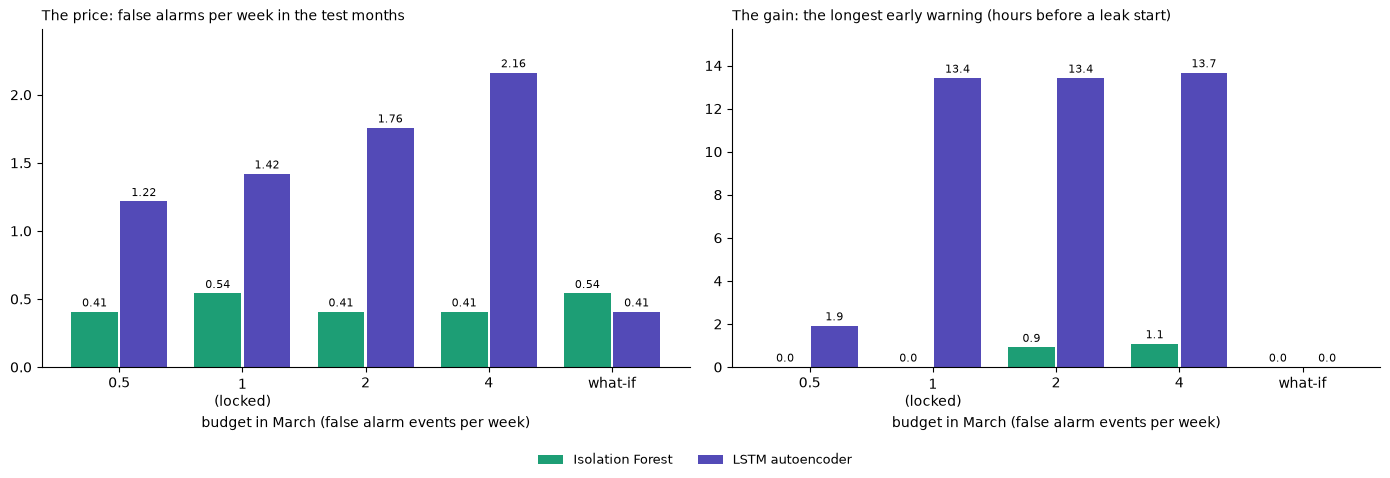

In [20]:
labels = list(settings)
places = np.arange(len(labels))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for offset, (model, name) in zip([-0.2, 0.2], MODEL_NAMES.items()):
    own = df_tradeoff[df_tradeoff["model"] == name].set_index("setting").loc[labels]
    for ax, column, number_format in [(axes[0], "false alarms per week", "{:.2f}"), (axes[1], "longest early warning (h)", "{:.1f}")]:
        bars = ax.bar(places + offset, own[column], width=0.38, color=MODEL_COLORS[model], label=name)
        ax.bar_label(bars, labels=[number_format.format(value) for value in own[column]], fontsize=8, padding=2)
for ax, title in zip(axes, ["The price: false alarms per week in the test months", "The gain: the longest early warning (hours before a leak start)"]):
    ax.set_xticks(places, labels=[label.replace(" ", "\n", 1) for label in labels])
    ax.set_xlabel("budget in March (false alarm events per week)")
    ax.margins(y=0.15)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.set_title(title, fontsize=10, loc="left")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

> **What we see:**
>
> - **LSTM autoencoder:** every looser budget adds false alarms, but the early warning hardly grows. Its only early warning is for leak 4, and leaks 1 to 3 stay at about their start (see the table). The stricter budget saves only a few false alarms, but its warning before leak 4 is much shorter. So the long early warning appears right at the locked budget, and looser budgets only add false alarms.
> - **Isolation Forest:** its limits stay close together, squeezed under the ceiling of its score (notebook 4.1). The looser budgets give it a short warning before leak 4, without more false alarm events: nearby alarms can join into one event (notebook 5.1), so a lower limit does not always mean more events.
> - **The what-if:** for the forest it gives the same results as its locked limit. For the LSTM, counting the long pump runs of March pushes the limit far up: the fewest false alarms of all its settings, but leak 4 is missed and no leak is caught before its start. Leaving the unusual March hours out (notebook 5.1) is what made the early warning of leak 4 possible.
>
> That the locked budget lands right where the long early warning appears is luck, not a choice: it can only be seen now, after the test, and it rests on a single leak. The official results stay those of notebook 5.2.

### What If Some False Alarms Were Real?

> Notebooks 3.2 and 5.3 found hours that look just like the reported leaks, although no failure is reported in them: the unusual hours of March, and the false alarms of the test months in which the pump never rested. If some of them were air losses that nobody reported, two things would change:
>
> 1. **Some false alarms were right.** The table counts the false alarm events of notebook 5.3 again, once without the events in which the pump never rested.
> 2. **The limits set on March were stricter than needed**, because some of the March "false alarms" were real. A looser budget would then be fair: the rows with budgets 2 and 4 above show what it would have given.
>
> This is a what-if too: the official count stays the one of notebook 5.2.

In [21]:
false_events = df_events[df_events["kind"] == "false alarm"]
real_table = pd.DataFrame({"false alarm events": false_events.groupby("model").size(),
                           "of them: pump never rested": false_events[false_events["looks_like"] == "pump never rested"].groupby("model").size()})
real_table = real_table.reindex(list(MODEL_NAMES.values())).fillna(0).astype(int)
real_table["false alarms per week"] = (real_table["false alarm events"] / healthy_weeks).round(2)
real_table["per week, without them"] = ((real_table["false alarm events"] - real_table["of them: pump never rested"]) / healthy_weeks).round(2)
display(real_table)
print(f"Budget used in March to set the limits: {LOCKED_BUDGET} false alarm event per week")
check("the events of notebook 5.3 hold the same false alarm events as notebook 5.2",
      (real_table["false alarm events"] == df_results.loc[real_table.index, "false alarm events"]).all())

,false alarm events,of them: pump never rested,false alarms per week,"per week, without them"
model,,,,
Isolation Forest,8,6,0.54,0.14
LSTM autoencoder,21,3,1.42,1.22


Budget used in March to set the limits: 1 false alarm event per week
PASS  the events of notebook 5.3 hold the same false alarm events as notebook 5.2


> **What we see:** most false alarm events of the forest are hours in which the pump never rested; without them, it would have very few false alarms left. The LSTM has only a few events of this kind and many more of other kinds (notebook 5.3), so it would still be above its budget. And even with fewer false alarms, the forest would still have missed most of the reported leaks.

## Speed

### Load the Two Models

> The models are loaded as in notebook 5.2, and the fingerprints of the two files are compared with the ones in `alarm_rules.json`, so we time exactly the locked models. The forest is a joblib file: only load joblib files you made yourself, because loading one can run code (notebook 4.1). The LSTM file is loaded with `weights_only=True`, which cannot run code.

In [22]:
forest = joblib.load(FOREST_FILE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
saved_lstm = torch.load(LSTM_FILE, map_location=device, weights_only=True)
lstm = LSTMAutoencoder(n_signals=len(saved_lstm["signals"]), memory_size=saved_lstm["memory_size"]).to(device)
lstm.load_state_dict(saved_lstm["state_dict"])
fingerprints = {os.path.basename(path): file_fingerprint(path=path) for path in [FOREST_FILE, LSTM_FILE]}

for name, value in fingerprints.items():
    print(f"{name}: {value[:16]}... | saved by notebook 5.1: {rules['model_files'][name][:16]}...")
print("LSTM runs on:", device.type)
check("the two model files are exactly the ones the limits were set for (their fingerprints match)", fingerprints == rules["model_files"])

isolation_forest.joblib: 5097501b4dda5e40... | saved by notebook 5.1: 5097501b4dda5e40...
lstm_autoencoder.pt: 84626161ecb960ac... | saved by notebook 5.1: 84626161ecb960ac...
LSTM runs on: cuda
PASS  the two model files are exactly the ones the limits were set for (their fingerprints match)


### One Window at a Time

> In live use, a new window ends every 5 minutes, and each model scores it alone. So we time exactly that: `SPEED_WINDOWS` test windows, spread evenly over the test months, scored one by one with a stopwatch. Each model starts from what notebook 3.1 saved: the forest from the summary numbers of the window, the LSTM from its ticks, already cut out of the grid.
>
> - The first call of a model is slower (memory is set up, and the GPU gets ready), so each model scores one window before the stopwatch starts.
> - The table shows the middle (median) time and the slowest time of one window, and how many times faster than needed the slowest time is: 5 minutes divided by it.
> - Every timed window must get the score that notebook 5.2 saved, to at least 4 digits. A window scored alone can differ in the very last digits from the same window scored in a group of 512, as notebook 5.2 did.

In [23]:
test_windows = df_windows[df_windows["split"] == "test"].reset_index(drop=True)
positions = np.linspace(0, len(test_windows) - 1, SPEED_WINDOWS).astype(int)
features = test_windows.loc[positions, signals_info["isolation_forest_features"]].reset_index(drop=True)
signal_columns = [grid_signals.index(signal) for signal in signals_info["signals"]]
cut = cut_windows(grid_values=grid_values, end_indices=test_windows.loc[positions, "end_index"].to_numpy(), window_steps=WINDOW_STEPS,
                  oil_index=grid_signals.index(OIL_COLUMN))
inputs = torch.from_numpy(np.ascontiguousarray(cut[:, :, signal_columns]))

anomaly_score(model=forest, features=features.iloc[[0]])
window_errors(model=lstm, windows=inputs[:1].to(device), batch_size=1)
seconds = {model: [] for model in MODEL_NAMES}
new_scores = {model: [] for model in MODEL_NAMES}
for position in tqdm(range(SPEED_WINDOWS), desc="Scoring one window at a time"):
    one_row, one_window = features.iloc[[position]], inputs[position:position + 1]
    started = time.perf_counter()
    new_scores["isolation_forest"].append(anomaly_score(model=forest, features=one_row)[0])
    seconds["isolation_forest"].append(time.perf_counter() - started)
    started = time.perf_counter()
    new_scores["lstm_autoencoder"].append(window_errors(model=lstm, windows=one_window.to(device), batch_size=1)[0][0])
    seconds["lstm_autoencoder"].append(time.perf_counter() - started)

needed_ms = STEP_MINUTES * 60 * 1000
speed_table = pd.DataFrame([{"model": name, "runs on": "GPU" if model == "lstm_autoencoder" and device.type == "cuda" else "CPU",
                             "middle time (ms)": np.median(seconds[model]) * 1000, "slowest time (ms)": np.max(seconds[model]) * 1000}
                            for model, name in MODEL_NAMES.items()]).set_index("model")
speed_table["times faster than needed"] = needed_ms / speed_table["slowest time (ms)"]
display(speed_table.style.format({"middle time (ms)": "{:.2f}", "slowest time (ms)": "{:.2f}", "times faster than needed": "{:,.0f}"}))
middle = speed_table["middle time (ms)"]
print(f"A new window every {STEP_MINUTES} minutes = {needed_ms:,} ms | faster for one window: {middle.idxmin()}, {middle.max() / middle.min():.1f} times")
check("every timed window got the score and the error that notebook 5.2 saved (to at least 4 digits)",
      np.array_equal(test_windows["end"].to_numpy(), df_test["end"].to_numpy())
      and all(np.allclose(new_scores[model], df_test.loc[positions, model].to_numpy(), rtol=1e-4, atol=0) for model in MODEL_NAMES))

Scoring one window at a time: 100%|██████████| 200/200 [00:03<00:00, 51.64it/s]


,runs on,middle time (ms),slowest time (ms),times faster than needed
model,,,,
Isolation Forest,CPU,12.88,37.64,"7,970"
LSTM autoencoder,GPU,1.61,6.00,"50,033"


A new window every 5 minutes = 300,000 ms | faster for one window: LSTM autoencoder, 8.0 times
PASS  every timed window got the score and the error that notebook 5.2 saved (to at least 4 digits)


> **What we see:** both models need only milliseconds for one window, even the slowest one, while a new window comes every 5 minutes: both could run live with a lot of room to spare (the last column). Which one is faster depends on the computer: the forest asks its trees one after another on the CPU, the LSTM reads the ticks of the window on the GPU when there is one. Either way, speed does not decide between the two models; what they catch does.

## Save

### What Will Be Written

> `results/tradeoff.csv`: one row per model and setting, with the limit, the leaks caught, every lead time, the longest early warning and the false alarms in the test months. A preview:

In [24]:
print(f"tradeoff: {df_tradeoff.shape[0]} rows x {df_tradeoff.shape[1]} columns")
display(df_tradeoff)
print(f"{os.path.relpath(TRADEOFF_FILE, ROOT_DIR)}: {'exists, will be replaced' if os.path.exists(TRADEOFF_FILE) else 'new file'}")

tradeoff: 10 rows x 14 columns


,model,setting,March windows counted,budget per week,limit,leaks caught,caught before the start,lead time leak 1 (h),lead time leak 2 (h),lead time leak 3 (h),lead time leak 4 (h),longest early warning (h),false alarm events,false alarms per week
0,Isolation Forest,0.5,unusual hours left out,0.5,0.735819,1,0,NaN,NaN,-3.416667,NaN,0.000000,6,0.405389
1,Isolation Forest,1 (locked),unusual hours left out,1.0,0.732597,1,0,NaN,NaN,-3.416667,NaN,0.000000,8,0.540519
2,Isolation Forest,2,unusual hours left out,2.0,0.729640,2,1,NaN,NaN,-1.166667,0.916667,0.916667,6,0.405389
3,Isolation Forest,4,unusual hours left out,4.0,0.725525,2,1,NaN,NaN,-1.166667,1.083333,1.083333,6,0.405389
4,Isolation Forest,what-if,every window counted,1.0,0.732766,1,0,NaN,NaN,-3.416667,NaN,0.000000,8,0.540519
5,LSTM autoencoder,0.5,unusual hours left out,0.5,0.896351,4,1,-1.583333,-0.083333,-0.166667,1.916667,1.916667,18,1.216167
6,LSTM autoencoder,1 (locked),unusual hours left out,1.0,0.780014,4,1,-1.583333,0.000000,-0.166667,13.416667,13.416667,21,1.418862
7,LSTM autoencoder,2,unusual hours left out,2.0,0.682509,4,1,-1.583333,0.000000,-0.083333,13.416667,13.416667,26,1.756686
8,LSTM autoencoder,4,unusual hours left out,4.0,0.604289,4,1,-1.583333,0.000000,-0.083333,13.666667,13.666667,32,2.162075
9,LSTM autoencoder,what-if,every window counted,1.0,2.018995,3,0,-1.583333,-0.500000,-0.583333,NaN,0.000000,6,0.405389


results\tradeoff.csv: new file


### Save the Trade-off Table

In [25]:
os.makedirs(RESULTS_DIR, exist_ok=True)
df_tradeoff.to_csv(TRADEOFF_FILE, index=False)
print(f"Saved {os.path.relpath(TRADEOFF_FILE, ROOT_DIR)} ({os.path.getsize(TRADEOFF_FILE) / 1024:,.1f} KB)")

Saved results\tradeoff.csv (1.7 KB)


### Read the File Back

In [26]:
tradeoff_back = pd.read_csv(TRADEOFF_FILE)
text_columns = ["model", "setting", "March windows counted"]
number_columns = [column for column in df_tradeoff.columns if column not in text_columns]
check("the saved trade-off table reads back the same",
      list(tradeoff_back.columns) == list(df_tradeoff.columns) and tradeoff_back[text_columns].equals(df_tradeoff[text_columns])
      and np.allclose(tradeoff_back[number_columns].to_numpy(dtype="float64"), df_tradeoff[number_columns].to_numpy(dtype="float64"), equal_nan=True))

PASS  the saved trade-off table reads back the same


## Result

### Final Result

> If every check passed, the locked budget gave back exactly the limits of notebook 5.1 and the results of notebook 5.2, both models were timed with the locked model files, and the trade-off table is saved. If a check failed, its name is printed.

In [27]:
failed = [name for name, ok in results.items() if not ok]
if results and not failed:
    print(f"ALL CHECKS PASSED ({len(results)} checks)")
else:
    print(f"{len(failed)} of {len(results)} checks FAILED:")
    for name in failed:
        print("  -", name)

ALL CHECKS PASSED (7 checks)


## Summary

> - With the locked budget of 1 false alarm event per week, the search gives back exactly the limits of notebook 5.1 and the results of notebook 5.2. Everything else here is a what-if after the test, and changes no result.
> - **LSTM autoencoder:** looser budgets add false alarms in the test months, but no earlier warning. A stricter budget saves a few false alarms, but shrinks the early warning of leak 4 to a short one.
> - **Isolation Forest:** its limits stay squeezed under the ceiling of its score. Looser budgets give it a short warning before leak 4, without more false alarm events, but it still misses most leaks.
> - **The what-if of notebook 5.1** (every March window counted): the same results for the forest. For the LSTM, the fewest false alarms of all its settings, but leak 4 is missed: leaving the unusual March hours out is what made its early warning possible.
> - **If the hours in which the pump never rested were air losses**, the forest would have very few false alarms left; the LSTM would still be above its budget.
> - **Speed:** both models score one window in milliseconds, and a new window comes every 5 minutes. Speed does not decide between them.
>
> **Next:** `notebooks/6_demo/6.1_prepare_demo.ipynb`